# Modelos de **boosting**

Mientras que los algoritmos de bagging y random forest entrenan múltiples árboles en paralelo, intentando reducir la varianza, los modelos de boosting siguen una lógica diferente y secuencial: entrenan árboles uno tras otro, y cada nuevo árbol intenta corregir los errores de los anteriores. El resultado es un modelo final de alta precisión, aunque más propenso a sobreajuste si no se controla.

A continuación, se va a mostrar como implementar dos de los algoritmos de boosting más populares, y compararemos su desempeño frente a un modelo de bosque aleatorio.

In [1]:
import pandas as pd

df = pd.read_csv(
    "http://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None,
    names=['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income'],
    na_values=' ?'
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df = df.dropna()

X = df.drop(columns=['income'])
y = df['income']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
    )

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

print(X_train.shape)
print(X_test.shape)

(24129, 14)
(6033, 14)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder,
)

orden = [' Preschool', ' 1st-4th', ' 5th-6th', ' 7th-8th', ' 9th', ' 10th', ' 11th', ' 12th',  # noqa: E501
         ' HS-grad',' Some-college', ' Assoc-acdm', ' Assoc-voc', ' Bachelors', ' Masters',
         ' Prof-school', ' Doctorate']
ore = OrdinalEncoder(categories=[orden], dtype='int')
ohe = OneHotEncoder(sparse_output=False, drop='if_binary')
te = TargetEncoder()

preprocessor = ColumnTransformer(
    transformers=[
        ('cod_education', ore, ['education']),
        ('cod_oh', ohe, ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex']),  # noqa: E501
        ('cod_te', te, ['native-country'])
    ], remainder='passthrough')

In [4]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import f1_score

ada = AdaBoostClassifier(
    random_state=1,
    )

ada_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', ada)
])

ada_model.fit(X_train, y_train)

train_score = f1_score(y_train, ada_model.predict(X_train), average='weighted')
test_score = f1_score(y_test, ada_model.predict(X_test), average='weighted')
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 0.840
Test score: 0.841


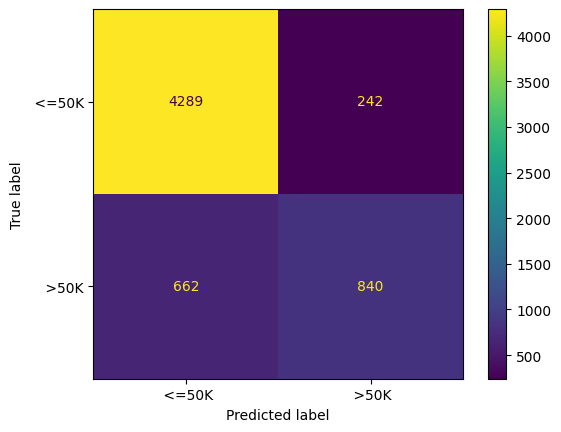

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(ada_model, X_test, y_test, display_labels=le.classes_);

In [6]:
from sklearn.metrics import classification_report

print(classification_report(y_test, ada_model.predict(X_test), target_names=le.classes_))

              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.90      4531
        >50K       0.78      0.56      0.65      1502

    accuracy                           0.85      6033
   macro avg       0.82      0.75      0.78      6033
weighted avg       0.84      0.85      0.84      6033



In [7]:
importances = ada_model.named_steps['classifier'].feature_importances_
features = ada_model.named_steps['preprocessor'].get_feature_names_out()

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
45,remainder__capital-gain,0.299552
10,cod_oh__marital-status_ Married-civ-spouse,0.220185
42,remainder__age,0.139727
44,remainder__education-num,0.090261
46,remainder__capital-loss,0.078168
47,remainder__hours-per-week,0.055164
0,cod_education__education,0.030747
18,cod_oh__occupation_ Exec-managerial,0.025909
32,cod_oh__relationship_ Own-child,0.020213
19,cod_oh__occupation_ Farming-fishing,0.015052


## Clasificadores gradient boosting

Gradient Boosting evoluciona la idea del boosting al tratar el proceso como un problema de **optimización de una función de pérdida**. La función de pérdida es MSE en los modelos de regresión y [log loss](https://scikit-learn.org/stable/modules/model_evaluation.html#log-loss) en los modelos de clasificación.

Así, en lugar de cambiar los pesos de los datos, cada nuevo árbol se entrena para predecir los **residuales** (el error o la diferencia entre el valor real y la predicción actual) del modelo previo.

Cada nuevo árbol es como un «parche» que minimiza una función de pérdida (error cuadrático, log-loss, etc.) usando el gradiente. El resultado final es:

$
\text{Predicción final} = \sum_{m=1}^{M} \eta \cdot (\text{árbol}_m)
$

Donde $\eta$ es la tasa de aprendizaje (learning rate), que controla la contribución de cada árbol.

Se va a entrenar un modelo  de gradient boosting con los parámetros por defecto:

In [8]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    random_state=1)

gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', gb)
])

gb_model.fit(X_train, y_train)

train_score = f1_score(y_train, gb_model.predict(X_train), average='weighted')
test_score = f1_score(y_test, gb_model.predict(X_test), average='weighted')
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 0.860
Test score: 0.860


Nótese como este modelo da mejores resultados que los anteriores, y no se sobreajusta:

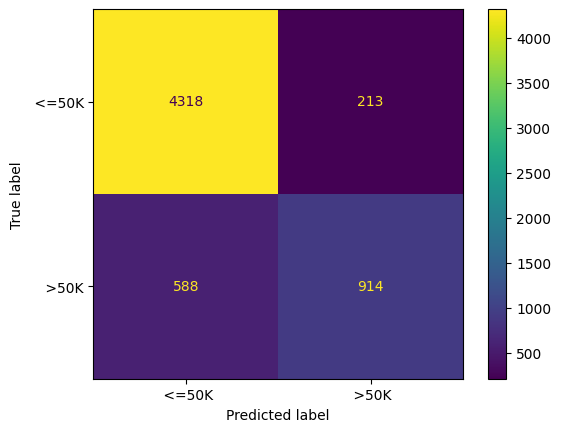

In [9]:
ConfusionMatrixDisplay.from_estimator(
    gb_model,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [10]:
print(classification_report(
    y_test,
    gb_model.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.92      4531
        >50K       0.81      0.61      0.70      1502

    accuracy                           0.87      6033
   macro avg       0.85      0.78      0.81      6033
weighted avg       0.86      0.87      0.86      6033



In [11]:
importances = gb_model.named_steps['classifier'].feature_importances_
features = gb_model.named_steps['preprocessor'].get_feature_names_out()

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
10,cod_oh__marital-status_ Married-civ-spouse,0.379435
45,remainder__capital-gain,0.208364
0,cod_education__education,0.126426
44,remainder__education-num,0.072010
46,remainder__capital-loss,0.056315
42,remainder__age,0.055423
47,remainder__hours-per-week,0.031713
18,cod_oh__occupation_ Exec-managerial,0.018765
24,cod_oh__occupation_ Prof-specialty,0.008416
22,cod_oh__occupation_ Other-service,0.004821


En un modelo de **gradient boosting** se pueden ajustar varios **hiperparámetros** para optimizar su rendimiento. Además de los ya vistos en los árboles de decisión y los bosques aleatorios, estos hiperparámetros adicionales se pueden sintonizar:

* **learning_rate:** Controla el tamaño del paso que se da en la dirección del gradiente durante el entrenamiento. Un valor grande puede conducir a un entrenamiento más rápido, pero también puede aumentar el riesgo de sobreajuste.
* **Criterio de parada (n_iter_no_change, validation_fraction y tol):** Determina cuándo se detiene el entrenamiento del modelo. Se pueden utilizar diferentes criterios como un cierto nivel de precisión o una mejora mínima en la precisión.

Se va a entrenar un modelo de *gradient boosting* sintonizando algunos de estos hiperparámetros:

In [14]:
from scipy.stats import uniform
from sklearn.model_selection import RandomizedSearchCV

dist = {
    'classifier__n_estimators':range(1, 201),
    'classifier__learning_rate':uniform(0.1,1),
    'classifier__min_samples_split':range(2,10),
    'classifier__max_depth':range(1,11),
    }

random_search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=dist,
    random_state=1,
    scoring='f1_weighted',
    n_iter=20
    )

random_search.fit(X_train, y_train)

print(f'Best validation score: {random_search.best_score_:.3f} with parameters: {random_search.best_params_}')  # noqa: E501
print(f'Train score: {random_search.score(X_train, y_train):.3f}')
print(f'Test score: {random_search.score(X_test, y_test):.3f}')

Best validation score: 0.860 with parameters: {'classifier__learning_rate': np.float64(0.5434528937795566), 'classifier__max_depth': 3, 'classifier__min_samples_split': 6, 'classifier__n_estimators': 97}
Train score: 0.880
Test score: 0.861


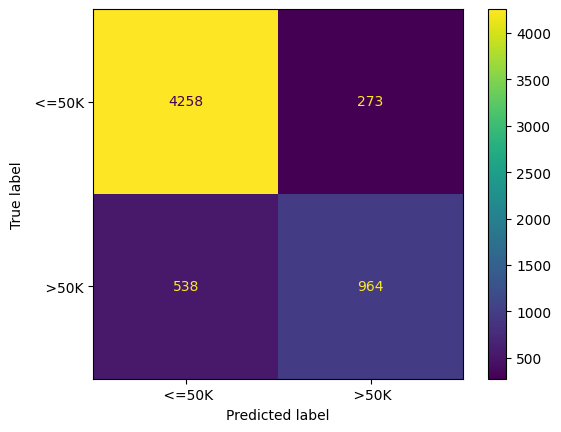

In [15]:
ConfusionMatrixDisplay.from_estimator(
    random_search.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [16]:
print(classification_report(
    y_test,
    random_search.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91      4531
        >50K       0.78      0.64      0.70      1502

    accuracy                           0.87      6033
   macro avg       0.83      0.79      0.81      6033
weighted avg       0.86      0.87      0.86      6033



El modelo mejora bastante y está menos desbalanceado.

In [17]:
best_gb_model = random_search.best_estimator_
importances = best_gb_model.named_steps['classifier'].feature_importances_
features = best_gb_model.named_steps['preprocessor'].get_feature_names_out()

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
10,cod_oh__marital-status_ Married-civ-spouse,0.361582
45,remainder__capital-gain,0.194552
0,cod_education__education,0.164199
42,remainder__age,0.057867
46,remainder__capital-loss,0.056478
47,remainder__hours-per-week,0.034709
44,remainder__education-num,0.028074
43,remainder__fnlwgt,0.020994
18,cod_oh__occupation_ Exec-managerial,0.014718
24,cod_oh__occupation_ Prof-specialty,0.009560


## Regresores gradient boosting

In [18]:
from pathlib import Path

data_dir = Path().resolve().parent / "data" / "raw"
data_name = "home_data.csv"
filepath = data_dir / data_name

df = pd.read_csv(filepath)
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [20]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=['id', 'date'], axis=1)

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
    )

print(X_train.shape)
print(X_test.shape)

(17290, 18)
(4323, 18)


In [22]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import root_mean_squared_error

ada_reg = AdaBoostRegressor(
    random_state=1,
)

ada_reg.fit(X_train, y_train)

train_score = root_mean_squared_error(y_train, ada_reg.predict(X_train))
test_score = root_mean_squared_error(y_test, ada_reg.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 295167.534
Test score: 313468.306


In [24]:
importances = ada_reg.feature_importances_
features = ada_reg.feature_names_in_

importances_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importances_df = importances_df[importances_df['Importance'] > 0]
importances_df.sort_values('Importance', ascending=False)

,Feature,Importance
2,sqft_living,0.357617
8,grade,0.244919
14,lat,0.090227
15,long,0.066218
9,sqft_above,0.053531
5,waterfront,0.053176
16,sqft_living15,0.034701
6,view,0.034425
17,sqft_lot15,0.016933
1,bathrooms,0.013072


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_reg = GradientBoostingRegressor(
    random_state=1
)

gb_reg.fit(X_train, y_train)

train_score = root_mean_squared_error(y_train, gb_reg.predict(X_train))
test_score = root_mean_squared_error(y_test, gb_reg.predict(X_test))
print(f'Train score: {train_score:.3f}')
print(f'Test score: {test_score:.3f}')

Train score: 113428.655
Test score: 155433.113


In [ ]:
dist = {
    'n_estimators':range(1, 201),
    'learning_rate':uniform(0.1, 1),
    'max_depth':range(1, 11)
}

random_search = RandomizedSearchCV(
    estimator=gb_reg,
    param_distributions=dist,
    random_state=1,
    scoring='neg_root_mean_squared_error',
    n_iter=20
    )

random_search.fit(X_train, y_train)

print(f'Best validation score: {-random_search.best_score_:.3f} with parameters: {random_search.best_params_}')  # noqa: E501
print(f'Train score: {root_mean_squared_error(y_train, random_search.predict(X_train)):.3f}')  # noqa: E501
print(f'Test score: {root_mean_squared_error(y_test, random_search.predict(X_test)):.3f}')  # noqa: E501

Best validation score: 120466.602 with parameters: {'learning_rate': np.float64(0.23002857211827768), 'max_depth': 6, 'n_estimators': 58}
Train score: 70032.872
Test score: 143049.702


In [27]:
gb_features = pd.DataFrame({
    'Feature': gb_reg.feature_names_in_, 
    'Importance': random_search.best_estimator_.feature_importances_
    })
gb_features.sort_values('Importance', ascending=False)

,Feature,Importance
8,grade,0.323740
2,sqft_living,0.266056
14,lat,0.170249
15,long,0.078196
5,waterfront,0.034147
16,sqft_living15,0.028133
11,yr_built,0.027217
9,sqft_above,0.015180
6,view,0.013338
13,zipcode,0.012879
